# Requirements to collpase requirements tables Note + Making Concordances Concord - Tony Gui

In [1]:
import pandas as pd
from IPython.display import clear_output
import numpy as np
from statsmodels.tsa.api import VAR
import os
from data_cleaning_functions import requirements_clean, concordance_PCE_clean, \
    find_intermediate_industries, concordance_PCQ_clean, get_sales_from_make_matrix, clean_make_matrix, \
    get_demand_shock_from_shaipro_output, get_expenditure_weights_from_shapiro_outputs,plot_shapiro_graph_from_shapiro_ouput,clean_bea_PQE_table, get_final_demand_from_use_table,\
        clean_bea_peq_table

from pathlib import Path
import matplotlib.pyplot as plt

script_dir = str(Path().resolve().parent)
file_path = os.path.join(script_dir) + "/" 
shapiro_file =  file_path + "Shapiro"
raw_data_path = file_path + "raw_bea_data" 

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
use_table = pd.read_excel(os.path.join(raw_data_path, "Use_SUT_Framework_2017_DET.xlsx"), sheet_name="2017")
intermediate_industries = find_intermediate_industries(use_table)
intermediate_industries = intermediate_industries.iloc[:, [0]]
intermediate_industries = intermediate_industries.sort_values(by="Industry")
# intermediate_industries
concordance = pd.read_excel(os.path.join(raw_data_path, "PCEBridge_2017_DET.xlsx"), sheet_name="2017")
concordance = concordance_PCE_clean(concordance)
# concordance
bea_quantities = pd.read_excel(os.path.join(raw_data_path, 'BEA Monthly Quantities.xlsx')) # read raw BEA quantities
bea_quantities = clean_bea_PQE_table(bea_quantities, "Quantities", long=True) 
bea_products = bea_quantities[["products"]].drop_duplicates()
# bea_products
# 1) sets
missing_inds = (
    intermediate_industries["Industry"]
    .astype(str).str.strip()
    .dropna().drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

used_products = set(
    concordance["PCE Bridge Products"]
    .astype(str).str.strip()
    .dropna().unique()
)

all_products = (
    (bea_products["products"] if isinstance(bea_products, pd.DataFrame) else bea_products)
    .astype(str).str.strip()
    .dropna().drop_duplicates()
)

unused_products = (
    all_products[~all_products.isin(used_products)]
    .sort_values()
    .reset_index(drop=True)
)

# 2) sanity check: need at least 143 unused products for a unique assignment
if len(unused_products) < len(missing_inds):
    raise ValueError(
        f"Not enough unused products: {len(unused_products)} unused vs {len(missing_inds)} industries."
    )

# 3) build the new concordance-style table (143 x 2)
bad_products = [
    "additional aggregates:",
    "durable goods:",
    "market-based personal consumption expenditures (pce):",
    "net expenditures abroad by u.s. residents",
    "net foreign travel",
    "nondurable goods:",
    "of which:"
]

unused_products_clean = unused_products[~unused_products.isin(bad_products)].reset_index(drop=True)

new_concordance_fill = pd.DataFrame({
    "PCE Bridge Products": unused_products_clean.iloc[:len(missing_inds)].to_list(),
    "PCE Bridge Industries": missing_inds.to_list(),
})

# new_concordance_fill
concordance_stacked = pd.concat([concordance, new_concordance_fill], ignore_index=True)
concordance_stacked

,PCE Bridge Products,PCE Bridge Industries
0,new domestic autos,automobile manufacturing
1,new domestic autos,motor vehicle body manufacturing
2,new foreign autos,automobile manufacturing
3,new light trucks,light truck and utility vehicle manufacturing
4,used autos,scrap
...,...,...
843,pce excluding food and energy2,valve and fittings other than plumbing
844,pce food and energy,"veneer, plywood, and engineered wood product m..."
845,pce goods excluding food and energy2,wholesale electronic markets and agents and br...
846,pce services excluding energy,wiring device manufacturing


In [3]:
new_concordance_fill

,PCE Bridge Products,PCE Bridge Industries
0,accommodations,air and gas compressor manufacturing
1,accounting and other business services,aircraft engine and engine parts manufacturing
2,admissions to specified spectator amusements,"all other forging, stamping, and sintering"
3,alcoholic beverages purchased for off-premises...,"all other miscellaneous professional, scientif..."
4,audio streaming and radio services (including ...,all other retail
...,...,...
138,pce excluding food and energy2,valve and fittings other than plumbing
139,pce food and energy,"veneer, plywood, and engineered wood product m..."
140,pce goods excluding food and energy2,wholesale electronic markets and agents and br...
141,pce services excluding energy,wiring device manufacturing


# 1. Load in Requirements Matrix 

In [4]:
requirements = pd.read_excel(os.path.join(raw_data_path, 'IxI_TR_2017_PRO_Det.xlsx'), sheet_name='2017')
requirements = requirements_clean(requirements)
requirements

2,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,federal general government (nondefense),postal service,federal electric utilities,other federal government enterprises,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),state and local government passenger transit,state and local government electric utilities,other state and local government enterprises
nan,,,,,,,,,,,,,,,,,,,,,
oilseed farming,1.279779,0.014409,0.004929,0.001729,0.001137,0.00316,0.023745,0.01215,0.048375,0.006966,...,-0.000636,0.000089,0.000451,0.002027,0.000422,0.0018,0.000539,0.002588,0.000153,0.000357
grain farming,0.002576,1.160693,0.005144,0.004288,0.002814,0.027177,0.103283,0.116055,0.147067,0.023998,...,0.0003,0.000189,0.00128,0.007513,0.001212,0.004625,0.001335,0.006901,0.000319,0.000772
vegetable and melon farming,0.000224,0.000785,1.037335,0.000679,0.000341,0.000616,0.000247,0.000177,0.000243,0.000105,...,0.000006,0.000004,0.00019,0.000907,0.00014,0.000308,0.000098,0.000019,0.000004,0.000009
fruit and tree nut farming,0.000245,0.000826,0.000647,1.026228,0.000361,0.000646,0.000507,0.000257,0.000495,0.000154,...,0.000032,0.000022,0.000933,0.003551,0.000496,0.002885,0.000562,0.000058,0.000017,0.000033
"greenhouse, nursery, and floriculture production",0.000769,0.002365,0.001809,0.001517,1.152284,0.002257,0.000938,0.000594,0.000857,0.000322,...,0.000109,0.000067,0.000186,0.000286,0.000117,0.000714,0.00162,0.001763,0.000117,0.00025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
state and local government (hospitals and health services),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000051,0.0,0.0,0.000001,0.0,1.000321,0.0,0.0,0.0,0.0
state and local government (other services),0.003345,0.010249,0.007965,0.007278,0.004364,0.008178,0.004048,0.002967,0.003636,0.001896,...,0.001066,0.001097,0.001879,0.002528,0.000768,0.00152,1.003711,0.003982,0.002619,0.002899
state and local government passenger transit,0.00012,0.000219,0.000136,0.000084,0.00011,0.000162,0.000203,0.000135,0.000233,0.000067,...,0.000143,0.000069,0.000191,0.000718,0.002467,0.000231,0.000541,1.008448,0.000119,0.000197


# 2. Calculate Delta

In [5]:
requirements = requirements.T
requirements = requirements.fillna(0)
delta = np.identity(len(requirements)) - np.linalg.inv(requirements)
delta

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_26903/3131717931.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  requirements = requirements.fillna(0)


array([[2.18230496e-01, 4.40683470e-04, 1.58573724e-04, ...,
        1.26996423e-06, 5.56401465e-04, 1.29145939e-02],
       [8.69983432e-03, 1.34678082e-01, 6.32280326e-04, ...,
        2.99931551e-06, 4.89773260e-04, 2.80987809e-02],
       [2.87985181e-03, 1.56677551e-03, 3.59778733e-02, ...,
        5.46202911e-07, 2.35506830e-03, 2.87196685e-02],
       ...,
       [7.30710756e-08, 8.52456228e-08, 5.12391827e-08, ...,
        8.09158658e-03, 8.42910778e-04, 2.33319882e-03],
       [1.34253220e-10, 3.09135792e-08, 2.01528360e-08, ...,
        9.69786639e-06, 5.65700212e-04, 1.13693450e-02],
       [7.91307821e-09, 4.43092759e-08, 3.36841533e-08, ...,
        1.53823502e-05, 4.58525716e-04, 7.31267212e-03]], shape=(402, 402))

# 2 (Making Concordances Concord) Adding Scrap, Used and secondhand goods and ROW adjustments to Delta

In [6]:
"""These 4 industries are found in the concordance table but not in the Reqirements table so I am 
adding them manually with row and column inputs of zero"""
concordance_but_not_requirments = ["Scrap", "Used and secondhand goods", "Rest of the world adjustment", "noncomparable imports"] 
delta = pd.DataFrame(delta, index=requirements.index, columns=requirements.columns)
delta = delta.reindex(index=requirements.index.append(pd.Index(concordance_but_not_requirments)).str.lower() , columns=requirements.columns.append(pd.Index(concordance_but_not_requirments)).str.lower() , fill_value=0)
delta

,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),state and local government passenger transit,state and local government electric utilities,other state and local government enterprises,scrap,used and secondhand goods,rest of the world adjustment,noncomparable imports
oilseed farming,2.182305e-01,4.406835e-04,1.585737e-04,1.608751e-04,1.585959e-04,4.303772e-03,3.059061e-04,1.258588e-03,5.658938e-04,6.267435e-04,...,0.000001,2.648539e-09,0.001996,1.269964e-06,0.000556,0.012915,0.0,0.0,0.0,0.0
grain farming,8.699834e-03,1.346781e-01,6.322803e-04,6.412868e-04,6.323431e-04,8.904588e-03,1.219444e-03,5.363358e-03,1.138804e-03,3.121992e-03,...,0.000004,6.914341e-09,0.007465,2.999316e-06,0.000490,0.028099,0.0,0.0,0.0,0.0
vegetable and melon farming,2.879852e-03,1.566776e-03,3.597787e-02,5.720080e-04,5.639853e-04,4.426647e-04,1.087635e-03,2.470001e-03,1.015753e-03,1.101832e-03,...,0.000002,1.644074e-08,0.006705,5.462029e-07,0.002355,0.028720,0.0,0.0,0.0,0.0
fruit and tree nut farming,7.340969e-04,1.550789e-03,6.284265e-04,2.553083e-02,5.581646e-04,4.351929e-04,1.076470e-03,3.931517e-03,1.005375e-03,1.872118e-03,...,0.000001,-6.199510e-09,0.006478,1.658714e-07,0.001537,0.020232,0.0,0.0,0.0,0.0
"greenhouse, nursery, and floriculture production",3.650259e-04,7.710037e-04,2.774939e-04,2.815021e-04,1.316849e-01,2.236586e-04,5.352380e-04,1.699724e-03,4.998527e-04,7.544837e-04,...,0.000001,-4.228297e-08,0.003166,2.865100e-07,0.000520,0.004565,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
other state and local government enterprises,7.913078e-09,4.430928e-08,3.368415e-08,5.390985e-08,1.475397e-08,-2.887312e-09,4.936176e-09,3.347282e-08,3.480128e-09,5.309115e-08,...,0.000009,-8.258717e-09,0.001245,1.538235e-05,0.000459,0.007313,0.0,0.0,0.0,0.0
scrap,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
used and secondhand goods,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
rest of the world adjustment,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0


# 2.5b Making Negative Values in Delta Zero

In [7]:
negative_count = (delta < 0).sum().sum()
percent_of_negatives_before = negative_count/402**2
delta[delta < 0] = 0
negative_count_new = (delta < 0).sum().sum()
percent_of_negatives_after = negative_count_new/402**2

# 2.5b Force negatives to be zero but adjust row sums to be same as before

In [8]:
# V = delta.sum(axis=0)
# P = delta[delta > 0].sum()
# delta.loc['norm'] = V/P
# last_values = delta.iloc[-1]
# delta[delta < 0] = 0
# delta = delta.iloc[:-1].div(last_values)
# delta

# Dealting with Intermediate Industries - Making Concordances Concord Section 3.3.1. - Operationalizing Industries without Products

# Step 1. Making Concordances Concord

In [9]:
# use_table = pd.read_excel(os.path.join(raw_data_path, "Use_SUT_Framework_2017_DET.xlsx"), sheet_name="2017")

# # Returns all industries with zero PCE 
# intermediate_industries = find_intermediate_industries(use_table)
# intermediate_industries = intermediate_industries.iloc[:, [0]]
# intermediate_industries = intermediate_industries.sort_values(by="Industry")
# intermediate_industries

# Steps 2 - 5. Making Concordances Concord - Loop over Intermediate Industries and Remove

In [10]:
# # For the Loop 
# big_lambda = np.eye(len(delta)) # create a big_lambda identity matrix that will become out final output
# big_lambda = pd.DataFrame(big_lambda)
# big_lambda = big_lambda.set_index(delta.index)
# big_lambda.columns = delta.index
# delta_industries = delta.index # save all the requirment table industries outside the loop 
# removed = [] # stores all removed industries through the loop 

# i = 0
# for row in intermediate_industries.iloc[::-1].itertuples(): # looping backwards
#     i += 1 
#     current = row.Industry # industry we are currently removing
#     # Create identity matrix for current loop iteration
#     phi_i = np.eye(len(delta) - (i - 1))
#     phi_i = pd.DataFrame(phi_i)
#     phi_i = phi_i.set_index(delta_industries)
#     phi_i.columns = delta_industries

#     current_intermediate_use_table = delta.copy() # use a new intermediates use matrix each time we do this
#     # Remove all the industries we've previously removed in earlier loop iterations 
#     current_intermediate_use_table.drop(columns=removed, inplace=True)
#     current_intermediate_use_table = current_intermediate_use_table.loc[[current]] # the row of the intermediates use table associated with the current industry  
#     current_intermediate_use_table.drop(columns=[current], inplace=True) # drop the column associated with the current industry so we dont include it in our sum
#     current_intermediate_use_table = current_intermediate_use_table.astype(float)
#     current_industry_sum = current_intermediate_use_table.loc[current].sum() # find sum of row

#     # just making sure that we aren't dividing by zero 
#     if current_industry_sum != 0:
#         current_intermediate_use_table = current_intermediate_use_table.astype(float)
#         current_intermediate_use_table.loc[current] = current_intermediate_use_table.loc[current] / current_industry_sum


#     current_intermediate_use_table = current_intermediate_use_table[sorted(current_intermediate_use_table.columns)] # sort the normazlied row alphabetically

#     # remove the current industry from intermediate list
#     intermediate_industries = intermediate_industries[intermediate_industries['Industry'] != current]
#     # drop the current industry column from phi_i and industry indexing
#     phi_i = phi_i.drop(columns=current)
#     delta_industries = delta_industries.drop(current) 
    
#     removed.append(current)

#     # Update phi_i with the current industry sale shares
#     phi_i.loc[current_intermediate_use_table.index] = current_intermediate_use_table.loc[current_intermediate_use_table.index].astype(np.float64).values
#     big_lambda_old = big_lambda
#     big_lambda = big_lambda @ phi_i

# Step 6. Making Concordances Concord - Converting IO matrix from sales shares to dollars

In [11]:
# make_matrix = pd.read_excel(os.path.join(raw_data_path, "Supply_2017_DET.xlsx"), sheet_name="2017")
# sales_vector = get_sales_from_make_matrix(make_matrix) # returns the sales for each industry

# # these industries are not in the make matrix so i will add them manually with zero entries to preserve df sizes
# industries_not_in_make_matrix = ["state and local government passenger transit", "state and local government electric utilities", \
#                       "secondary smelting and alloying of aluminum", "federal electric utilities"]
# not_in_make_matrix = pd.DataFrame({'Industries': industries_not_in_make_matrix, 'Sales': [0,0,0,0]})
# sales_vector = pd.concat([sales_vector, not_in_make_matrix], ignore_index=True)
# sales_vector.set_index('Industries', inplace=True)

# # repeat the sales vector n times to make a sales matrix
# sales_repeated = pd.DataFrame({f'{i}': sales_vector['Sales'].values for i in range(1, len(delta))})
# sales_repeated.set_index(sales_vector.index, inplace=True)
# sales_matrix = pd.concat([sales_vector, sales_repeated], axis=1)
# sales_matrix.columns = delta.columns

# # Y is IO matrix in dollars 
# Y = delta * sales_matrix 

# Step 7. Making Concordances Concord - Value Added for the Economy

In [12]:
# sum_Y = Y.sum(axis=1).to_frame()
# sum_Y.columns = ['Sales']
# VA_pre_transformation = (sales_vector - sum_Y).sum()

# Step 8. Making Concordances Concord - IO Matrix in USD

In [13]:
# # new IO matrix in USD 
# Y_tilde = big_lambda.T @ Y @ big_lambda
# sales_tilde = big_lambda.T @ sales_vector

# # Verifing that economy wide value added is identical to the pre-transformation level
# sum_Y_tilde = Y_tilde.sum(axis=1).to_frame()
# sum_Y_tilde.columns = ['Sales']
# VA_post_transformation = (sales_tilde - sum_Y_tilde).sum()
# # VA_post_transformation

In [14]:
# """Pre transformation and post transformation are not the same"""
# differnece = VA_post_transformation - VA_pre_transformation
# differnece

# Step 9. Making Concordances Concord - Calculating New Delta

In [15]:
# recip_sales = 1/sales_tilde
# sales_tilde_repeated = pd.DataFrame({f'{i}': recip_sales['Sales'].values for i in range(1, len(delta))})
# sales_tilde_repeated.set_index(recip_sales.index, inplace=True)
# sales_tilde_matrix = pd.concat([recip_sales, sales_tilde_repeated], axis=1)
# sales_tilde_matrix.columns = delta.columns

# delta_tilde = Y_tilde * sales_tilde_matrix
# delta = delta_tilde
# # delta

# End of Making Concordances Concord - Back to Requirements to Collapse Requirements Table

# 3. Merge Concordance with Delta

In [16]:
# concordance = pd.read_excel(os.path.join(raw_data_path, "PCEBridge_2017_DET.xlsx"), sheet_name="2017")
# PEQ_concordance = pd.read_excel(os.path.join(raw_data_path, "PEQBridge_2017_DET.xlsx"), sheet_name="2017")

# pce = concordance_PCE_clean(concordance).copy()
# peq = concordance_PCE_clean(PEQ_concordance).copy()

# # keep all PCE rows; only use PEQ for industries not already covered by PCE
# pce_industries = set(pce["PCE Bridge Industries"])
# peq_only = peq.loc[~peq["PCE Bridge Industries"].isin(pce_industries)].copy()

# master_concordance = pd.concat([pce, peq_only], ignore_index=True)
# master_concordance = master_concordance.drop_duplicates(
#     subset=["PCE Bridge Industries", "PCE Bridge Products"]
# ).reset_index(drop=True)

# master_concordance["PCE Bridge Industries"] = master_concordance["PCE Bridge Industries"].replace(
#     "pump and pumping equipment manufacturing",
#     "measuring, dispensing, and other pumping equipment manufacturing"
# )

# concordance = master_concordance


# concordance

# concordance = pd.read_excel(os.path.join(raw_data_path, "PCEBridge_2017_DET.xlsx"), sheet_name="2017")
# concordance = concordance_PCE_clean(concordance)
# # concordance

concordance = concordance_stacked
concordance

,PCE Bridge Products,PCE Bridge Industries
0,new domestic autos,automobile manufacturing
1,new domestic autos,motor vehicle body manufacturing
2,new foreign autos,automobile manufacturing
3,new light trucks,light truck and utility vehicle manufacturing
4,used autos,scrap
...,...,...
843,pce excluding food and energy2,valve and fittings other than plumbing
844,pce food and energy,"veneer, plywood, and engineered wood product m..."
845,pce goods excluding food and energy2,wholesale electronic markets and agents and br...
846,pce services excluding energy,wiring device manufacturing


In [17]:
"""'federal electric utilities', 'secondary smelting and alloying of aluminum', 'state and local government electric utilities', 'state and local government passenger transit' 
are not an intermediate industry nor do they exist in the PCE concordance so we will simply drop"""
industries_in_requirments = set(delta.columns)
indsutries_in_concordance = set(concordance["PCE Bridge Industries"])
industires_not_in_concordance = industries_in_requirments - indsutries_in_concordance
delta = delta.drop(index=industires_not_in_concordance, columns=industires_not_in_concordance, errors='ignore')
delta

,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,postal service,other federal government enterprises,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),other state and local government enterprises,scrap,used and secondhand goods,rest of the world adjustment,noncomparable imports
oilseed farming,2.182305e-01,4.406835e-04,1.585737e-04,1.608751e-04,1.585959e-04,0.004304,3.059061e-04,1.258588e-03,5.658938e-04,6.267435e-04,...,2.444614e-05,0.000032,0.000001,2.648539e-09,0.001996,0.012915,0.0,0.0,0.0,0.0
grain farming,8.699834e-03,1.346781e-01,6.322803e-04,6.412868e-04,6.323431e-04,0.008905,1.219444e-03,5.363358e-03,1.138804e-03,3.121992e-03,...,5.113396e-05,0.000047,0.000004,6.914341e-09,0.007465,0.028099,0.0,0.0,0.0,0.0
vegetable and melon farming,2.879852e-03,1.566776e-03,3.597787e-02,5.720080e-04,5.639853e-04,0.000443,1.087635e-03,2.470001e-03,1.015753e-03,1.101832e-03,...,4.708953e-05,0.000078,0.000002,1.644074e-08,0.006705,0.028720,0.0,0.0,0.0,0.0
fruit and tree nut farming,7.340969e-04,1.550789e-03,6.284265e-04,2.553083e-02,5.581646e-04,0.000435,1.076470e-03,3.931517e-03,1.005375e-03,1.872118e-03,...,3.593147e-07,0.000074,0.000001,0.000000e+00,0.006478,0.020232,0.0,0.0,0.0,0.0
"greenhouse, nursery, and floriculture production",3.650259e-04,7.710037e-04,2.774939e-04,2.815021e-04,1.316849e-01,0.000224,5.352380e-04,1.699724e-03,4.998527e-04,7.544837e-04,...,3.902815e-07,0.000076,0.000001,0.000000e+00,0.003166,0.004565,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
other state and local government enterprises,7.913078e-09,4.430928e-08,3.368415e-08,5.390985e-08,1.475397e-08,0.000000,4.936176e-09,3.347282e-08,3.480128e-09,5.309115e-08,...,3.599164e-04,0.000059,0.000009,0.000000e+00,0.001245,0.007313,0.0,0.0,0.0,0.0
scrap,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
used and secondhand goods,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
rest of the world adjustment,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0


In [18]:
in_num_products = concordance['PCE Bridge Industries'].value_counts()

delta_product_columns = pd.DataFrame(index=delta.index, columns=concordance['PCE Bridge Products'])

for column in delta_product_columns: 
    industry = concordance.loc[concordance['PCE Bridge Products'] == column, 'PCE Bridge Industries'].values
    delta_product_columns[column] = delta[industry] / in_num_products[industry]

delta_product_cr = pd.DataFrame(columns=delta_product_columns.columns)
lst_for_industry = []
for row in delta_product_columns.index:
    final_value = delta_product_columns.loc[row] / in_num_products[row]
    products = concordance[concordance['PCE Bridge Industries'] == row]['PCE Bridge Products'].tolist()
    for product in products: 
        lst_for_industry.append(row)
        final_value_row = pd.DataFrame(final_value).T
        final_value_row.index = [product]
        
        delta_product_cr = pd.concat([delta_product_cr, final_value_row])

industry = pd.DataFrame(lst_for_industry, columns=['industry'])
industry.index = delta_product_cr.index
delta_product_cr = pd.concat([delta_product_cr, industry], axis = 1)
delta_product_cr

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_26903/3732902829.py:19: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  delta_product_cr = pd.concat([delta_product_cr, final_value_row])


,new domestic autos,new domestic autos,new foreign autos,new light trucks,used autos,used autos,used light trucks,used light trucks,tires,tires,...,paramedical services,pce energy goods and services1,pce excluding energy,pce excluding food,pce excluding food and energy2,pce food and energy,pce goods excluding food and energy2,pce services excluding energy,personal care and clothing services,industry
market-based pce personal care and clothing services,0.000002,0.000004,0.000002,3.326239e-07,0.0,0.0,0.0,0.0,0.001048,0.0,...,6.042182e-08,0.0,7.405335e-07,2.626054e-09,2.437941e-06,8.410907e-07,0.000419,0.000026,9.379869e-07,oilseed farming
cereals,0.000001,0.000002,0.000001,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,1.596410e-08,0.0,4.420982e-07,8.390552e-09,4.635154e-07,1.653374e-07,0.000107,0.000014,2.720663e-08,grain farming
processed fruits and vegetables,0.000001,0.000002,0.000001,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,1.596410e-08,0.0,4.420982e-07,8.390552e-09,4.635154e-07,1.653374e-07,0.000107,0.000014,2.720663e-08,grain farming
pets and related products,0.000001,0.000002,0.000001,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,1.596410e-08,0.0,4.420982e-07,8.390552e-09,4.635154e-07,1.653374e-07,0.000107,0.000014,2.720663e-08,grain farming
food furnished to employees (including military),0.000001,0.000002,0.000001,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,1.596410e-08,0.0,4.420982e-07,8.390552e-09,4.635154e-07,1.653374e-07,0.000107,0.000014,2.720663e-08,grain farming
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
less: expenditures in the united states by nonresidents,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,rest of the world adjustment
government employees' expenditures abroad,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,noncomparable imports
private employees' expenditures abroad,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,noncomparable imports
u.s. travel outside the united states,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,noncomparable imports


# 4. Collapse columns

In [19]:
delta_products = delta_product_cr.T.groupby(delta_product_cr.columns).sum().T
# delta_products

# 5. Make Matrix to Sales

In [20]:
make_matrix = pd.read_excel(os.path.join(raw_data_path, "Supply_2017_DET.xlsx"), sheet_name='2017')
sales = get_sales_from_make_matrix(make_matrix)
# sales

# 6. Merge concordance with sales 

In [21]:
product_sales = pd.merge(concordance, sales, left_on='PCE Bridge Industries', right_on='Industries')
product_sales = product_sales[["PCE Bridge Products", "Industries", 'Sales']]
# product_sales

# 7. Group sum of Sales for every Product

In [22]:
# calculates the number of product categories an Industry belongs to 
product_sales['In#Products'] = product_sales['Industries'].map(product_sales['Industries'].value_counts())
product_sales["Ratio_in_Product"] = product_sales['Sales'] / product_sales['In#Products'] 
product_sales['Sales_Sum'] = product_sales.groupby('PCE Bridge Products')['Ratio_in_Product'].transform('sum')
# product_sales

# 8. Sales Share 

In [23]:
product_sales['Sale Share'] = product_sales["Ratio_in_Product"] / product_sales["Sales_Sum"]
product_sales = product_sales.rename(columns={'Industries': 'industry'})
product_sales = product_sales.rename(columns={'PCE Bridge Products': 'product'})
# product_sales

# 9. Merge Sale shares and Delta

In [24]:
df_reset = delta_products.reset_index()
delta_products = df_reset.rename(columns={'index': 'product'})
delta_products_saleshare = delta_products.merge(product_sales, how = 'inner', on = ['industry', 'product'])
delta_products_saleshare = delta_products_saleshare.drop(columns=['Sales_Sum', "Ratio_in_Product", "In#Products", "Sales", "industry"])
delta_products_saleshare = delta_products_saleshare.set_index(delta_products_saleshare.columns[0])
# delta_products_saleshare

# 10. weightTimesDeltaValue + 11.

In [25]:
# Convert from Wide to Long
delta_final = delta_products_saleshare.reset_index().melt(id_vars=[delta_products_saleshare.index.name, "Sale Share"],
                                var_name="Column Products", value_name="value")

# Just Renaming and Reordering
delta_final = delta_final.rename(columns={delta_products_saleshare.index.name: "Row Products"})
delta_final = delta_final[['Row Products', 'Column Products', 'value', 'Sale Share']]
# Calculating weightTimesDeltaValue
delta_final["weightTimesDeltaValue"] = delta_final["value"] * delta_final["Sale Share"]

# Sum weightTimesDeltaValue grouping by Row Products AND Column Products
delta_final = delta_final.groupby(['Row Products', 'Column Products']).sum()
delta_final
# Convert Back to Wide Format 
delta_final = delta_final.pivot_table(values='weightTimesDeltaValue', index='Row Products', columns='Column Products')

# Removes Index and Column Names cuz it looks better. Both Index and Columns are simply Product Categories now
delta_final.columns.name = None 
delta_final.index.name = None 


labels_to_drop = ["government employees' expenditures abroad", "private employees' expenditures abroad","u.s. travel outside the united states","u.s. student expenditures"]
delta_final = delta_final.drop(index=labels_to_drop, columns=labels_to_drop, errors="ignore")

delta_final = delta_final.T

In [26]:
delta_final

,accessories and parts,accommodations,accounting and other business services,admissions to specified spectator amusements,air transportation,alcohol in purchased meals,alcoholic beverages purchased for off-premises consumption,all other professional medical services,"amusement parks, campgrounds, and related recreational services","audio discs, tapes, vinyl, and permanent digital downloads",...,video and audio streaming and rental,"video discs, tapes, and permanent digital downloads",vocational rehabilitation services,watches,water supply and sewage maintenance,water transportation,window coverings,wine,women's and girls' clothing,workers' compensation
accessories and parts,0.147975,0.009607,0.007321,0.005168,0.000001,0.000538,0.005877,0.000595,0.000664,0.000159,...,0.001223,0.000198,0.01136,0.005219,0.000215,0.002017,0.006197,0.010054,0.000944,0.000046
accommodations,0.000001,0.05535,0.0,0.0,0.0,0.000013,0.0,0.0,0.000001,0.0,...,0.0,0.0,0.0,0.0,0.000008,0.000007,0.0,0.0,0.0,0.0
accounting and other business services,0.000001,0.0,0.31673,0.000004,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000001,0.000003,0.0,0.0,0.0,0.0
admissions to specified spectator amusements,0.004513,0.009252,0.015573,0.108496,0.0,0.000039,0.0,0.0,0.000001,0.0,...,0.0,0.0,0.000001,0.000506,0.000056,0.0,0.000048,0.000001,0.000069,0.0
air transportation,0.000137,0.000207,0.000151,0.000177,0.00004,0.000126,0.000521,0.000086,0.000226,0.000219,...,0.000439,0.000069,0.000148,0.000071,0.000059,0.000518,0.000061,0.000204,0.000056,0.000002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000051,0.000025,0.000006,0.001304,0.005109,0.000548,0.000323,0.000067,0.000356,0.000112,...,0.000286,0.000094,0.000268,0.00001,0.00058,0.010148,0.002153,0.000689,0.00029,0.0
window coverings,0.000064,0.000013,0.000016,0.000001,0.0,0.000019,0.000001,0.000016,0.000058,0.000001,...,0.000001,0.0,0.000504,0.000008,0.0,0.000012,0.001659,0.0,0.000017,0.0
wine,0.0,0.0,0.0,0.0,0.000188,0.001331,0.0,0.0,0.000386,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000032,0.0,0.062783,0.0,0.0
women's and girls' clothing,0.000642,0.000015,0.0,0.0,0.0,0.000011,0.000002,0.000062,0.000053,0.000001,...,0.000002,0.000014,0.000136,0.000004,0.000001,0.000012,0.003337,0.0,0.00245,0.0


# Fixing Products with no price, quantity or expendiuture data 

In [27]:

target_products = pd.Index(delta_final.index).astype(str).str.strip().str.lower()

def prep_long(df, value_col):
    out = df.copy()
    out["products"] = out["products"].astype(str).str.strip().str.lower()
    out["date"] = pd.to_datetime(out["date"], errors="coerce")
    out[value_col] = pd.to_numeric(out[value_col], errors="coerce")
    out = out[out["products"].isin(target_products)]
    out = out[["products", "date", value_col]].drop_duplicates()
    return out.reset_index(drop=True)


In [28]:
bea_prices = pd.read_excel(os.path.join(raw_data_path, 'Quarterly Price Index.xlsx'))
bea_prices = clean_bea_PQE_table(bea_prices, "Prices", long=True)
bea_prices = bea_prices[bea_prices['products'].isin(delta_final.index)]
bea_prices = bea_prices.drop_duplicates()
bea_prices['Prices'] = bea_prices['Prices'].replace('---', 0).astype(float)
bea_prices = bea_prices.fillna(0)

# raw_peq_exp = pd.read_excel(
#     os.path.join(raw_data_path, "PEQ Quarterly Expenditure.xlsx"),
#     header=None
# )

# raw_peq_price = pd.read_excel(
#     os.path.join(raw_data_path, "PEQ Quarterly Price.xlsx"),
#     header=None
# )

# PEQ_expenditures = clean_bea_peq_table(raw_peq_exp, "Expenditures", long=True)
# PEQ_Price = clean_bea_peq_table(raw_peq_price, "Prices", long=True)


bea_expenditures = pd.read_excel(os.path.join(raw_data_path, 'Quarterly Expenditure.xlsx'))
bea_expenditures = clean_bea_PQE_table(bea_expenditures, "Expenditures", long=True)
bea_expenditures = bea_expenditures[bea_expenditures['products'].isin(delta_final.index)]
bea_expenditures = bea_expenditures.drop_duplicates()
bea_expenditures['Expenditures'] = bea_expenditures['Expenditures'].replace('---', 0).astype(float)
bea_expenditures = bea_expenditures.fillna(0)


bea_quantities = pd.read_excel(os.path.join(raw_data_path, 'Quarterly Quantity Index.xlsx')) # read raw BEA quantities
bea_quantities = clean_bea_PQE_table(bea_quantities, "Quantities", long=True) 
bea_quantities = bea_quantities[bea_quantities['products'].isin(delta_final.index)] # drop products taht delta doesnt have
bea_quantities = bea_quantities.drop_duplicates()
bea_quantities['Quantities'] = bea_quantities['Quantities'].replace('---', 0).astype(float)
bea_quantities = bea_quantities.fillna(0)

# """Generate Quantity from Expenditure and Price"""

# # -----------------------------
# # PEQ quantity index from PEQ expenditures + PEQ prices
# # fixed-base index with 2017 average = 100
# # -----------------------------

# peq_q = (
#     PEQ_expenditures[["products", "date", "Expenditures"]]
#     .merge(
#         PEQ_Price[["products", "date", "Prices"]],
#         on=["products", "date"],
#         how="inner",
#         validate="one_to_one"
#     )
#     .copy()
# )

# # make sure types are clean
# peq_q["date"] = pd.to_datetime(peq_q["date"], errors="coerce")
# peq_q["Expenditures"] = pd.to_numeric(peq_q["Expenditures"], errors="coerce")
# peq_q["Prices"] = pd.to_numeric(peq_q["Prices"], errors="coerce")

# # invalid prices -> missing
# peq_q.loc[peq_q["Prices"] <= 0, "Prices"] = np.nan

# # real quantity-like level before normalization
# peq_q["real_unnormalized"] = peq_q["Expenditures"] / (peq_q["Prices"] / 100)

# # 2017 average real level by product
# base_2017 = (
#     peq_q.loc[peq_q["date"].dt.year == 2017]
#     .groupby("products", as_index=False)["real_unnormalized"]
#     .mean()
#     .rename(columns={"real_unnormalized": "base_2017_real"})
# )

# # merge base back
# peq_q = peq_q.merge(base_2017, on="products", how="left", validate="many_to_one")

# # quantity index, 2017 average = 100
# peq_q["Quantities"] = 100 * peq_q["real_unnormalized"] / peq_q["base_2017_real"]

# # clean infinities
# peq_q["Quantities"] = peq_q["Quantities"].replace([np.inf, -np.inf], np.nan)

# # final long table
# PEQ_quantities = peq_q[["products", "date", "Quantities"]].copy()


# peq_name_map = {
#     "electrical equipment, n.e.c.": "electrical equipment, not elsewhere classified",
#     "special industry machinery, n.e.c.": "special industry machinery, not elsewhere classified",
# }

# for df in [PEQ_expenditures, PEQ_Price, PEQ_quantities]:
#     df["products"] = (
#         df["products"]
#         .astype(str)
#         .str.strip()
#         .str.lower()
#         .str.replace(r"\d+$", "", regex=True)   # removes footnote markers like autos1
#         .str.replace(r"\s+", " ", regex=True)
#         .replace(peq_name_map)
#     )

# PEQ_expenditures = PEQ_expenditures[PEQ_expenditures['products'].isin(delta_final.index)]
# PEQ_Price = PEQ_Price[PEQ_Price['products'].isin(delta_final.index)]
# PEQ_quantities = PEQ_quantities[PEQ_quantities['products'].isin(delta_final.index)]

# PEQ_expenditures["Expenditures"] = pd.to_numeric(PEQ_expenditures["Expenditures"], errors="coerce").fillna(0)
# PEQ_Price["Prices"] = pd.to_numeric(PEQ_Price["Prices"], errors="coerce").fillna(0)

# # stack PEQ onto BEA
# bea_prices = (
#     pd.concat([bea_prices, PEQ_Price], ignore_index=True)
#     .drop_duplicates(subset=["products", "date"], keep="first")
#     .reset_index(drop=True)
# )

# bea_expenditures = (
#     pd.concat([bea_expenditures, PEQ_expenditures], ignore_index=True)
#     .drop_duplicates(subset=["products", "date"], keep="first")
#     .reset_index(drop=True)
# )

# bea_quantities = (
#     pd.concat([bea_quantities, PEQ_quantities], ignore_index=True)
#     .drop_duplicates(subset=["products", "date"], keep="first")
#     .reset_index(drop=True)
# )

# for df in [bea_prices, bea_quantities, bea_expenditures, PEQ_Price, PEQ_expenditures, PEQ_quantities]:
#     df["products"] = df["products"].astype(str).str.strip().str.lower()
#     df["date"] = pd.to_datetime(df["date"], errors="coerce")


bea_PQE_merged = pd.merge(left=bea_quantities, right=bea_prices, on=['products', 'date'], how='outer')
bea_PQE_merged = pd.merge(left=bea_PQE_merged, right=bea_expenditures, on=['products', 'date'], how='outer')

# dropping this because 2024-10 has no data yet 
bea_PQE_merged = bea_PQE_merged.dropna(subset=['Expenditures'])

dates = list(set(bea_expenditures["date"]) & set(bea_prices["date"]) & set(bea_quantities["date"]))
dates.sort() # get all BEA data quarterly dates

cols_to_check = ['Quantities', 'Prices', 'Expenditures']

# Create filtered DataFrame where at least one value is missing or zero
products_with_zero_somwhere = bea_PQE_merged[
    bea_PQE_merged[cols_to_check].isnull().any(axis=1) |
    (bea_PQE_merged[cols_to_check] == 0).any(axis=1)
]

all_bad_products_dict = {} # For every date products that dont have a value somewhere

for date in dates:
    bad_products_currnet = products_with_zero_somwhere[products_with_zero_somwhere['date'] == date]["products"]
    all_bad_products_dict[date] = bad_products_currnet.tolist()

""""For BEA I will set the entire BEA row to zero if any of the price, quantity or expenditure data is missing"""
zero_mask = (bea_PQE_merged[cols_to_check] == 0).any(axis=1)
# Set all three columns to 0 where the mask is True
bea_PQE_merged.loc[zero_mask, cols_to_check] = 0

bea_prices = bea_PQE_merged[["products", "date", "Prices"]]

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_26903/2992001331.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bea_prices['Prices'] = bea_prices['Prices'].replace('---', 0).astype(float)
/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_26903/2992001331.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('futu

# 1. Calculate PCE Inflation

In [29]:
bea_expenditures_wide = bea_expenditures.pivot(index='products', columns='date', values='Expenditures')

# to_zero = peq_only["PCE Bridge Products"].astype(str).str.strip().str.lower().drop_duplicates()
to_zero = new_concordance_fill["PCE Bridge Products"]
date_cols = [c for c in bea_expenditures_wide.columns if c != "products"]

bea_expenditures_wide.loc[
    bea_expenditures_wide.index.isin(to_zero),
    date_cols
] = 0

P = bea_prices.pivot(index='products', columns='date', values='Prices')
log_P = P.applymap(lambda x: np.log(x) if x > 0 else 0)
log_P = log_P.iloc[:, 12:]

Pi = np.log(P.replace(0, np.nan)).diff(axis=1)
Pi = Pi.replace([np.inf, -np.inf], np.nan).fillna(0.0)

bea_expenditures_weights = bea_expenditures_wide.div(bea_expenditures_wide.sum(axis=0), axis=1)

PCE_Inflation = bea_expenditures_weights * Pi
PCE_Inflation = PCE_Inflation.fillna(0)

Quarterly_inflation = np.ones((1, PCE_Inflation.shape[0])) @ PCE_Inflation
Quarterly_inflation = Quarterly_inflation.T

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_26903/1435487231.py:13: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  log_P = P.applymap(lambda x: np.log(x) if x > 0 else 0)


In [30]:
bea_expenditures_weights

date,1959-10-01,1960-01-01,1960-04-01,1960-07-01,1960-10-01,1961-01-01,1961-04-01,1961-07-01,1961-10-01,1962-01-01,...,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,0.002865,0.002903,0.002941,0.002906,0.002907,0.002876,0.002893,0.003023,0.003040,0.003093,...,0.003627,0.003653,0.003708,0.003719,0.003679,0.003635,0.003613,0.003594,0.003629,0.003606
accommodations,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
accounting and other business services,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
admissions to specified spectator amusements,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
air transportation,0.002077,0.002053,0.002068,0.002220,0.002256,0.002196,0.002348,0.002375,0.002460,0.002589,...,0.008836,0.008593,0.008929,0.008969,0.008873,0.009230,0.009459,0.009369,0.009482,0.009342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,...,0.000310,0.000325,0.000326,0.000321,0.000336,0.000322,0.000340,0.000351,0.000344,0.000356
window coverings,0.002706,0.002626,0.002615,0.002567,0.002561,0.002577,0.002546,0.002535,0.002520,0.002518,...,0.001712,0.001715,0.001706,0.001693,0.001655,0.001623,0.001613,0.001610,0.001607,0.001584
wine,0.001791,0.001751,0.001739,0.001764,0.001785,0.001819,0.001818,0.001823,0.001867,0.001949,...,0.003694,0.003671,0.003637,0.003604,0.003595,0.003565,0.003554,0.003540,0.003521,0.003492


# Time varying A based on bad pordudcts

In [31]:
delta_final_monthly = {}

for date, zero_products in all_bad_products_dict.items():
    current_delta = delta_final.copy()
    zero_products = current_delta.index.intersection(zero_products)

    current_delta.loc[zero_products, :] = 0
    current_delta.loc[:, zero_products] = 0

    delta_final_monthly[date] = current_delta

# 2. Calculate the Leontief Inverse

In [32]:
from numpy.linalg import inv

B_monthly = {}
A_monthly = {}

A_orig = delta_final.to_numpy(dtype=float)
v = 1 - A_orig.sum(axis=0)
V = np.diag(v)

for date, delta in delta_final_monthly.items():
    delta = delta.reindex(index=delta_final.index, columns=delta_final.columns)

    A = delta.to_numpy(dtype=float)
    B = V @ inv(np.eye(A.shape[0]) - A)

    A_monthly[date] = pd.DataFrame(A, index=delta.index, columns=delta.columns)
    B_monthly[date] = pd.DataFrame(B, index=delta.index, columns=delta.columns)

# 3. Calculate PCE to VA Shares: Omega

In [33]:
bea_expenditures_weights.columns = pd.to_datetime(bea_expenditures_weights.columns)
quarters = sorted([ts for ts in bea_expenditures_weights.columns if ts in B_monthly])

Omega_monthly = {}

for ts in quarters:
    B = B_monthly[ts]
    w = bea_expenditures_weights[ts].to_numpy(dtype=float)

    omega_ts = B.to_numpy(dtype=float) @ w

    Omega_monthly[ts] = pd.Series(
        omega_ts,
        index=B.index,
        name=ts
    )

Omega = pd.DataFrame(Omega_monthly)

# Get PI_VA

In [34]:
Pi_np = Pi.to_numpy(dtype=float)
A_np = np.asarray(A, dtype=float)

numerator_np = Pi_np - A_np.T @ Pi_np

numerator = pd.DataFrame(numerator_np, index=Pi.index, columns=Pi.columns)

col_sums_A = A_np.sum(axis=0)
col_sums_A = 1 - col_sums_A
col_sums_A = np.where(col_sums_A == 0, np.nan, col_sums_A)

Pi_VA_NP = numerator / col_sums_A[:, None]
Pi_VA = pd.DataFrame(Pi_VA_NP, index=numerator.index, columns=numerator.columns)

In [35]:
PI_PCE_APPROX = (Omega * Pi_VA).sum(axis=0) 
  
merged = pd.concat(
    [PI_PCE_APPROX, Quarterly_inflation],
    axis=1,
    keys=["PI_PCE_APPROX", "Monthly_Inflation"]
)

merged["diff"] = (merged["PI_PCE_APPROX"] - merged["Monthly_Inflation"]).abs()
merged

,PI_PCE_APPROX,Monthly_Inflation,diff
,0,0,
1959-10-01,0.000000,0.000000,0.000000e+00
1960-01-01,0.000842,0.000847,4.112985e-06
1960-04-01,0.005091,0.005091,7.296018e-08
1960-07-01,0.003565,0.003565,1.634567e-07
1960-10-01,0.004349,0.004349,2.711627e-07
...,...,...,...
2024-01-01,0.008822,0.008822,1.734723e-18
2024-04-01,0.006403,0.006403,8.673617e-19
2024-07-01,0.004205,0.004205,8.673617e-19


# Find Sales

In [36]:
# calculate sales in product and time period
sales = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
                   'products': pd.Series(dtype='str'),
                   'sales': pd.Series(dtype='float')})

dates = [d for d in dates if d.year >= 1960 and d.year< 2025]

for date in dates:

    gamma = Omega[date]
    omega = B_monthly.get(date)
 
    # filter expenditures for the current date
    expenditures_date = bea_expenditures[bea_expenditures['date'] == date][['products', 'Expenditures']].set_index('products')
    expenditures_date = expenditures_date.sort_index()
    expenditures_date = expenditures_date.apply(pd.to_numeric, errors='coerce')

    diag_matrix = np.diag(gamma)

    x = np.identity(len(omega)) - (omega.T @ diag_matrix)

    sales_date = np.linalg.inv(x) @ expenditures_date

    sales_date['date'] = date
    sales_date['products'] = expenditures_date.index
    sales_date.rename(columns={'Expenditures': 'sales'}, inplace=True)

    sales = pd.concat([sales, sales_date], ignore_index=True)

In [37]:
dates = [d for d in dates if d.year >= 1960 and d.year< 2025]

# Find Prices of Intermediates

In [38]:
rows = []
for d_idx, date in enumerate(dates):

    prices_date = (
        bea_prices.loc[bea_prices["date"] == date, ["products", "Prices"]]
        .set_index("products")
        .sort_index()
    )

    log_prices = np.log(prices_date["Prices"])
    log_prices.replace(-np.inf, 0, inplace=True)

    gamma = Omega[date]
    omega = B_monthly.get(date)

    for i in gamma.index:
        rows.append((
            date,
            i,
            np.exp(omega.loc[i] @ log_prices)
        ))

    # keep VS Code renderer alive
    if d_idx % 1 == 0:
        clear_output(wait=True)

intermediates = pd.DataFrame(
    rows,
    columns=["date", "products", "intermediates"]
)

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


# Find Price of Value Added

In [39]:
# calculate prices of value added
value_added = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
                   'products': pd.Series(dtype='str'),
                   'value_added': pd.Series(dtype='float')})

for date in dates:
    # filter prices for the current date
    prices_date = bea_prices[bea_prices['date'] == date][['products', 'Prices']].set_index('products')
    prices_date = prices_date.sort_index()

    # filter intermediates for the current date
    intermediates_date = intermediates[intermediates['date'] == date][['products', 'intermediates']].set_index('products')
    intermediates_date = intermediates_date.sort_index()

    gamma_series = Omega[date]

    value_added_date = np.exp((1/(1 - gamma_series.sort_index()))*(np.log(prices_date['Prices']) - gamma_series.sort_index() * np.log(intermediates_date['intermediates'])))

    value_added_date = value_added_date.reset_index().rename(columns={0: 'value_added'})
    value_added_date['date'] = date
    value_added_date.rename(columns={"index": "products"}, inplace=True)

    value_added = pd.concat([value_added, value_added_date], ignore_index=True)

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, me

# Sales and Value Added VAR

In [40]:
lags = 4
residuals_part = []

for product in gamma.index:

    product_bad_dates = products_with_zero_somwhere[products_with_zero_somwhere["products"] == product]
    calculated = pd.merge(left=value_added, right=sales, on=['products', 'date'], how='inner')
    calculated = calculated[calculated['products'] == product][['date', 'value_added', 'sales']].sort_values(['date'])
    calculated = calculated.set_index('date')

    if not product_bad_dates.empty: 
        calculated = calculated[~calculated.index.isin(product_bad_dates['date'])] # remove rows before we have all time series data
    
    calculated['value_added'] = np.log(calculated['value_added']).diff()
    calculated['sales'] = np.log(calculated['sales']).diff()

    calculated.replace([np.inf, -np.inf, np.nan], 0, inplace=True)
    
    full_index_calc = pd.date_range(start=calculated.index.min(), end=calculated.index.max(), freq='QS')
    calculated = calculated.reindex(full_index_calc)

    model_calculated = VAR(calculated)
    result_calculated = model_calculated.fit(lags)

    residuals_calculated = result_calculated.resid.reset_index()
    residuals_calculated['products'] = product
    
    residuals_part.append(residuals_calculated)
    

IO_residuals = pd.concat(residuals_part, ignore_index=True)
IO_residuals.rename(columns={'index': 'date', 'value_added': 'residual_value_added', 'sales': 'residual_sales'}, inplace=True)
IO_residuals = IO_residuals.groupby(['date', 'products']).sum(min_count=1).reset_index()
IO_residuals = IO_residuals.sort_values(['date', 'products'])

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


KeyboardInterrupt: 

# Price and Quantity VAR

In [ ]:
lags = 4
residual_temp = []

for product in gamma.index:

    original = bea_PQE_merged[bea_PQE_merged['products'] == product][['date', 'Prices', 'Quantities']].sort_values(['date'])
    original = original.set_index('date')

    original.dropna(inplace=True)

    original['Prices'] = np.log(original['Prices']).diff()
    original['Quantities'] = np.log(original['Quantities']).diff()
     

    original.replace([np.inf, -np.inf], np.nan, inplace=True)
    original.dropna(inplace=True)

    full_index = pd.date_range(start=original.index.min(), end=original.index.max(), freq='QS')
    original = original.reindex(full_index)

    model_original = VAR(original)
    result_original = model_original.fit(lags)

    residuals_original = result_original.resid.reset_index()
    residuals_original['products'] = product
    
    residual_temp.append(residuals_original)
    
residuals_normal = pd.concat(residual_temp, ignore_index=True)
residuals_normal.rename(columns={'index': 'date', 'Prices': 'residual_prices', 'Quantities': 'residual_quantities'}, inplace=True)
residuals_normal = residuals_normal.groupby(['date', 'products']).sum(min_count=1).reset_index()
residuals_normal = residuals_normal.sort_values(['date', 'products'])

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, me

# Classification of Price of Value Added and Real Production

In [ ]:
residuals_normal['majority_demand'] = ((residuals_normal['residual_prices'] * residuals_normal['residual_quantities']) >= 0).astype(int)
residuals_normal['majority_supply'] = ((residuals_normal['residual_prices'] * residuals_normal['residual_quantities']) < 0).astype(int)

IO_residuals['majority_demand_a'] = ((IO_residuals['residual_value_added'] * IO_residuals['residual_sales']) >= 0).astype(int)
IO_residuals['majority_supply_a'] = ((IO_residuals['residual_value_added'] * IO_residuals['residual_sales']) < 0).astype(int)

In [ ]:
def plot_graphs(data, plot_title, plot_text):
    """Function to Graph Stacked Plot"""
    data = data.loc[data.index >= pd.Timestamp('1970-01-01')]

    supply_inflation = data[["annual_supply_inflation"]].copy()
    supply_inflation.rename(columns={'annual_supply_inflation': 'Supply Inflation'}, inplace=True)

    demand_inflation = data[["annual_demand_inflation"]].copy()
    demand_inflation.rename(columns={'annual_demand_inflation': 'Demand Inflation'}, inplace=True)

    supply_inflation['supply_pos'] = supply_inflation['Supply Inflation'].apply(lambda x: x if x > 0 else 0)
    demand_inflation['demand_pos'] = demand_inflation['Demand Inflation'].apply(lambda x: x if x > 0 else 0)
    supply_inflation['supply_neg'] = supply_inflation['Supply Inflation'].apply(lambda x: x if x < 0 else 0)
    demand_inflation['demand_neg'] = demand_inflation['Demand Inflation'].apply(lambda x: x if x < 0 else 0)

    demand_inflation = demand_inflation.iloc[:-1]
    supply_inflation = supply_inflation.iloc[:-1]

    plt.figure(figsize=(26, 12))

    plt.stackplot(supply_inflation.index, demand_inflation['demand_pos'], supply_inflation['supply_pos'], colors= ["#008000", "#FF0000"], labels = ["Deamnd", "Supply"])
    plt.stackplot(supply_inflation.index, demand_inflation['demand_neg'], supply_inflation['supply_neg'], colors= ["#008000", "#FF0000"])
    plt.xlabel('Date')
    plt.ylabel('Inflation')
    plt.title(f'{plot_title}')
    plt.legend()

    plt.text(0.02, 0.95, 
         f'{plot_text}', 
         transform=plt.gca().transAxes, fontsize=9,
         bbox=dict(facecolor='white', alpha=0.8))

    return plt


def quarter_over_quarter_product_inflation(df):
    """Calculate quarter-over-quarter product inflation."""
    df = df.sort_values(by=['products', 'date']).copy()
    df['inflation percent'] = (
        df.groupby('products')['prices']
        .transform(lambda x: (x - x.shift(1)) / x.shift(1))
    )
    return df


In [ ]:
# IO VAR classifictions
D_IO = IO_residuals.pivot(index='products', columns='date', values='majority_demand_a')
# Shapiro VAR classifictions
D_shapiro = residuals_normal.pivot(index='products', columns='date', values='majority_demand')

In [ ]:
# Use the combined quarterly BEA + PEQ prices
prices_wide = bea_prices.pivot(index='products', columns='date', values='Prices')
prices_wide = prices_wide.sort_index(axis=1)

# Keep only products used in the classification
prices_wide = prices_wide.loc[prices_wide.index.intersection(D_shapiro.index)]
prices_wide = prices_wide[~prices_wide.index.duplicated(keep='first')]

# Quarter-over-quarter inflation
inflation = prices_wide.pct_change(axis=1)

# Expenditure weights from combined quarterly BEA + PEQ expenditures
bea_expenditures_wide = bea_expenditures.pivot(index='products', columns='date', values='Expenditures')
bea_expenditures_wide = bea_expenditures_wide.sort_index(axis=1)
bea_expenditures_wide = bea_expenditures_wide.loc[bea_expenditures_wide.index.intersection(D_shapiro.index)]
bea_expenditures_wide = bea_expenditures_wide[~bea_expenditures_wide.index.duplicated(keep='first')]

to_zero = new_concordance_fill["PCE Bridge Products"]
date_cols = [c for c in bea_expenditures_wide.columns if c != "products"]

bea_expenditures_wide.loc[
    bea_expenditures_wide.index.isin(to_zero),
    date_cols
] = 0


expenditure_weights = bea_expenditures_wide.div(bea_expenditures_wide.sum(axis=0), axis=1)

expenditure_weights

date,1959-10-01,1960-01-01,1960-04-01,1960-07-01,1960-10-01,1961-01-01,1961-04-01,1961-07-01,1961-10-01,1962-01-01,...,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,0.002865,0.002903,0.002941,0.002906,0.002907,0.002876,0.002893,0.003023,0.003040,0.003093,...,0.003627,0.003653,0.003708,0.003719,0.003679,0.003635,0.003613,0.003594,0.003629,0.003606
accommodations,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
accounting and other business services,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
admissions to specified spectator amusements,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
air transportation,0.002077,0.002053,0.002068,0.002220,0.002256,0.002196,0.002348,0.002375,0.002460,0.002589,...,0.008836,0.008593,0.008929,0.008969,0.008873,0.009230,0.009459,0.009369,0.009482,0.009342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,...,0.000310,0.000325,0.000326,0.000321,0.000336,0.000322,0.000340,0.000351,0.000344,0.000356
window coverings,0.002706,0.002626,0.002615,0.002567,0.002561,0.002577,0.002546,0.002535,0.002520,0.002518,...,0.001712,0.001715,0.001706,0.001693,0.001655,0.001623,0.001613,0.001610,0.001607,0.001584
wine,0.001791,0.001751,0.001739,0.001764,0.001785,0.001819,0.001818,0.001823,0.001867,0.001949,...,0.003694,0.003671,0.003637,0.003604,0.003595,0.003565,0.003554,0.003540,0.003521,0.003492


In [ ]:
expenditure_weights[pd.Timestamp("1959-10-01 00:00:00")].sum(0)

np.float64(1.0)

In [ ]:
# IO Classification Aggregated Monthly Inflation
inflation_parts_IO = {}

dates = [d for d in expenditure_weights if d.year >= 1961 and d.year< 2025]

for date in dates:
    current_demand = D_IO[str(date)] # all products calssified as demand for this period
    current_supply = 1 - current_demand # all products calssified as supply for this period

    """Note that these are not BEA inflation and weights they are Ben's Value added and Omega"""
    current_weights_va = Omega[date] # all product weights for this period
    value_added_inflation = Pi_VA[date] # all product specific inflation for this period

    demand_inflation = (current_demand * current_weights_va * value_added_inflation).sum() # Aggregated montly demand driven inflation
    supply_inflation = (current_supply * current_weights_va * value_added_inflation).sum() # Aggregated montly supply driven inflation

    inflation_parts_IO[date] = [demand_inflation, supply_inflation] # Store each month's data

# Final demand and supply driven inflation
inflation_IO_final = pd.DataFrame(inflation_parts_IO, index=['demand_inflation', 'supply_inflation'])
inflation_IO_final = inflation_IO_final.T

# Shapiro Classification Aggregated Monthly Inflation
inflation_parts_shapiro = {}

for date in dates:
    current_demand = D_shapiro[str(date)]
    current_supply = 1 - current_demand

    current_weights = expenditure_weights[date]
    current_inflation = inflation[date]

    demand_inflation = (current_demand * current_weights * current_inflation).sum()
    supply_inflation = (current_supply * current_weights * current_inflation).sum()

    inflation_parts_shapiro[date] = [demand_inflation, supply_inflation]


inflation_shapiro_final = pd.DataFrame(inflation_parts_shapiro, index=['demand_inflation', 'supply_inflation'])
inflation_shapiro_final = inflation_shapiro_final.T

In [ ]:
# IO VAR classifications
D_IO = IO_residuals.pivot(index='products', columns='date', values='majority_demand_a')

# force fake-concordance products to be supply (0) for all dates
fake_products = (
    new_concordance_fill["PCE Bridge Products"]
    .astype(str)
    .str.strip()
    .str.lower()
    .drop_duplicates()
)

D_IO.index = D_IO.index.astype(str).str.strip().str.lower()
D_IO.loc[D_IO.index.intersection(fake_products), :] = 1

D_IO

date,1961-01-01,1961-04-01,1961-07-01,1961-10-01,1962-01-01,1962-04-01,1962-07-01,1962-10-01,1963-01-01,1963-04-01,...,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
accommodations,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
accounting and other business services,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
admissions to specified spectator amusements,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
air transportation,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
window coverings,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0
wine,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0


In [ ]:
# IO Classification - 4-quarter Supply Inflation
inflation_IO_final['annual_supply_inflation'] = (
    (inflation_IO_final['supply_inflation'].add(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
)

# IO Classification - 4-quarter Demand Inflation
inflation_IO_final['annual_demand_inflation'] = (
    (inflation_IO_final['demand_inflation'].add(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
)

# Shapiro Classification - 4-quarter Supply Inflation
inflation_shapiro_final['annual_supply_inflation'] = (
    (inflation_shapiro_final['supply_inflation'].add(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
)

# Shapiro Classification - 4-quarter Demand Inflation
inflation_shapiro_final['annual_demand_inflation'] = (
    (inflation_shapiro_final['demand_inflation'].add(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
)


In [ ]:
inflation_shapiro_final

,demand_inflation,supply_inflation,annual_supply_inflation,annual_demand_inflation
1961-01-01,0.000848,0.000916,NaN,NaN
1961-04-01,0.000540,-0.000726,NaN,NaN
1961-07-01,0.001237,0.002049,NaN,NaN
1961-10-01,0.000302,0.000260,0.249929,0.293049
1962-01-01,0.000683,0.003459,0.504580,0.276452
...,...,...,...,...
2023-10-01,0.003999,0.000818,1.565114,1.358756
2024-01-01,0.004015,0.004950,1.437064,1.414232
2024-04-01,0.003618,0.002879,1.195269,1.547680
2024-07-01,0.003298,0.001017,0.969380,1.501419


In [ ]:
inflation_IO_final

,demand_inflation,supply_inflation,annual_supply_inflation,annual_demand_inflation
1961-01-01,-0.000012,0.001701,NaN,NaN
1961-04-01,-0.002019,0.001728,NaN,NaN
1961-07-01,0.001317,0.001897,NaN,NaN
1961-10-01,0.001012,-0.000495,0.483853,0.029490
1962-01-01,0.002039,0.002001,0.513927,0.234631
...,...,...,...,...
2023-10-01,0.003128,0.001584,1.221467,1.638825
2024-01-01,0.005570,0.003252,1.137888,1.655582
2024-04-01,0.005655,0.000748,0.834370,1.859997
2024-07-01,0.003427,0.000779,0.637665,1.789578


<module 'matplotlib.pyplot' from '/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/matplotlib/pyplot.py'>

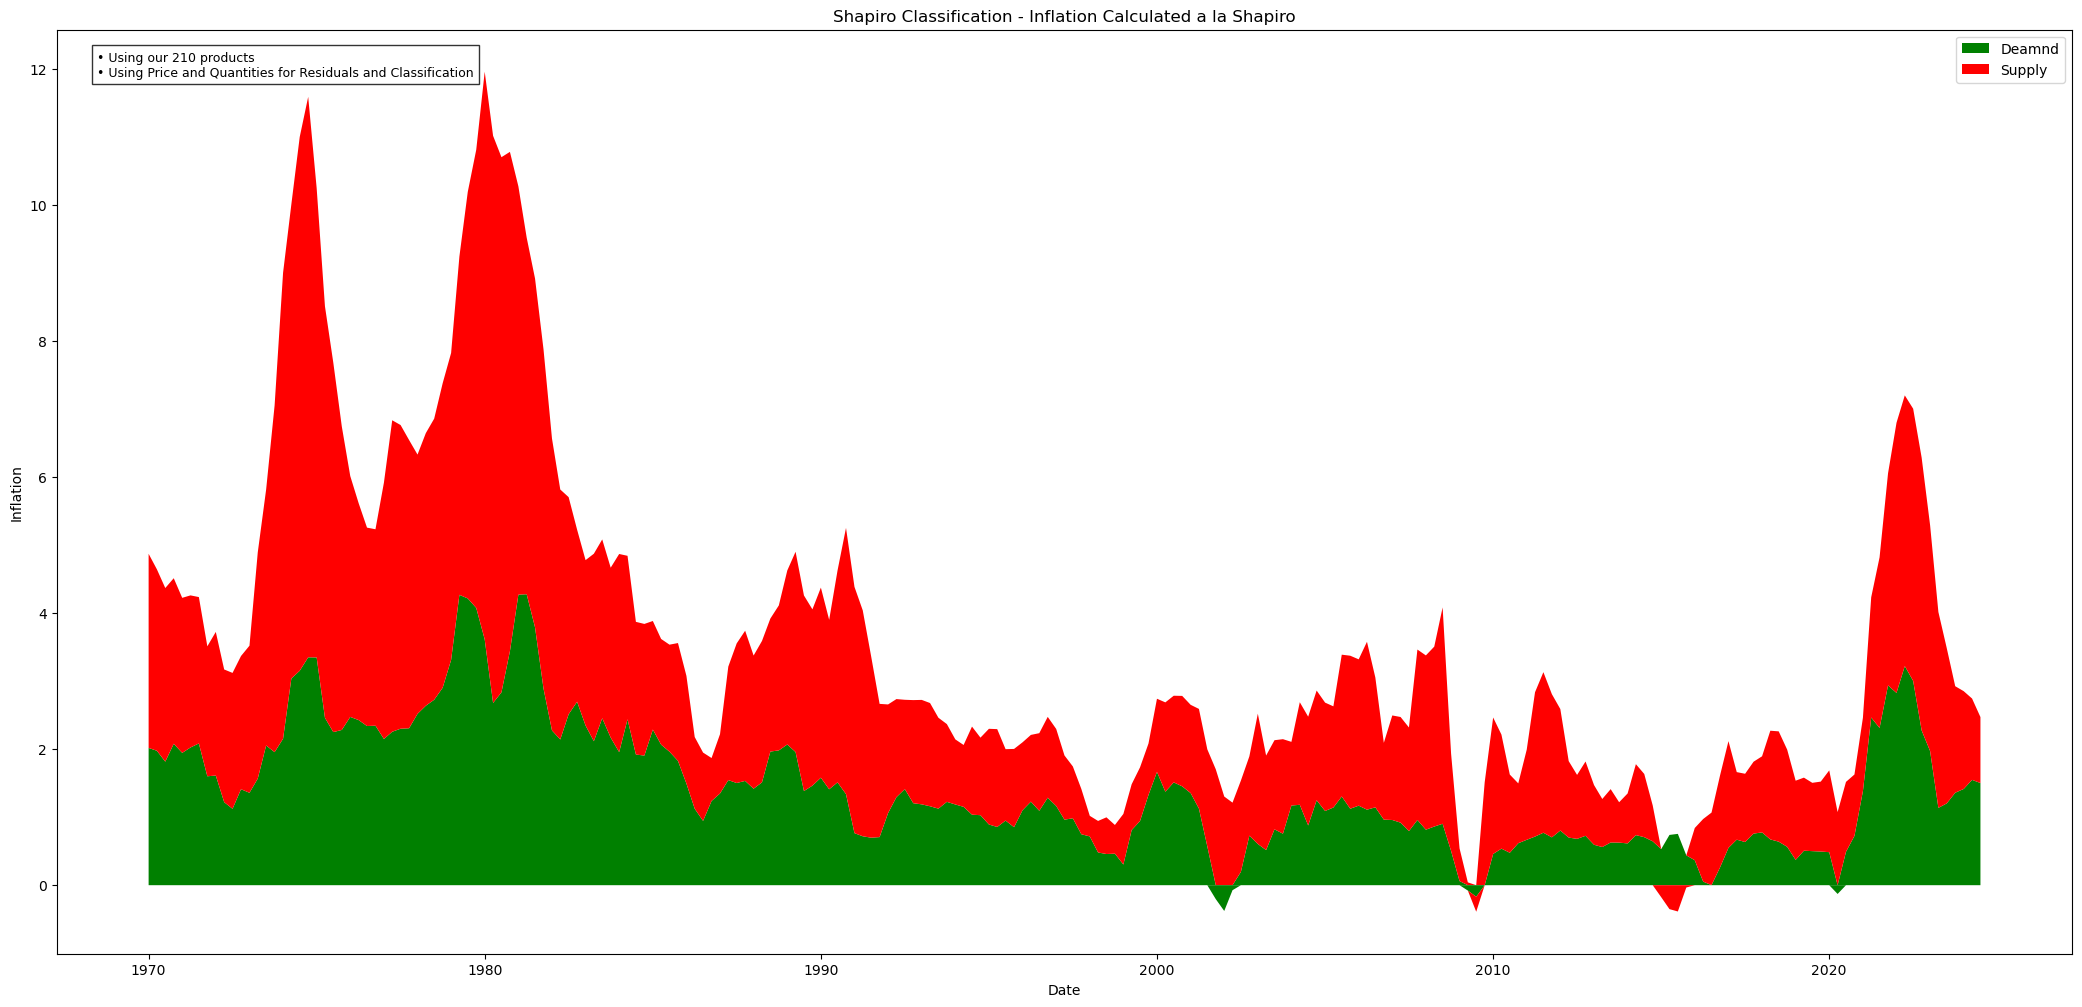

In [ ]:
plot_graphs(inflation_shapiro_final, "Shapiro Classification - Inflation Calculated a la Shapiro", "• Using our 210 products \n• Using Price and Quantities for Residuals and Classification")

<module 'matplotlib.pyplot' from '/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/matplotlib/pyplot.py'>

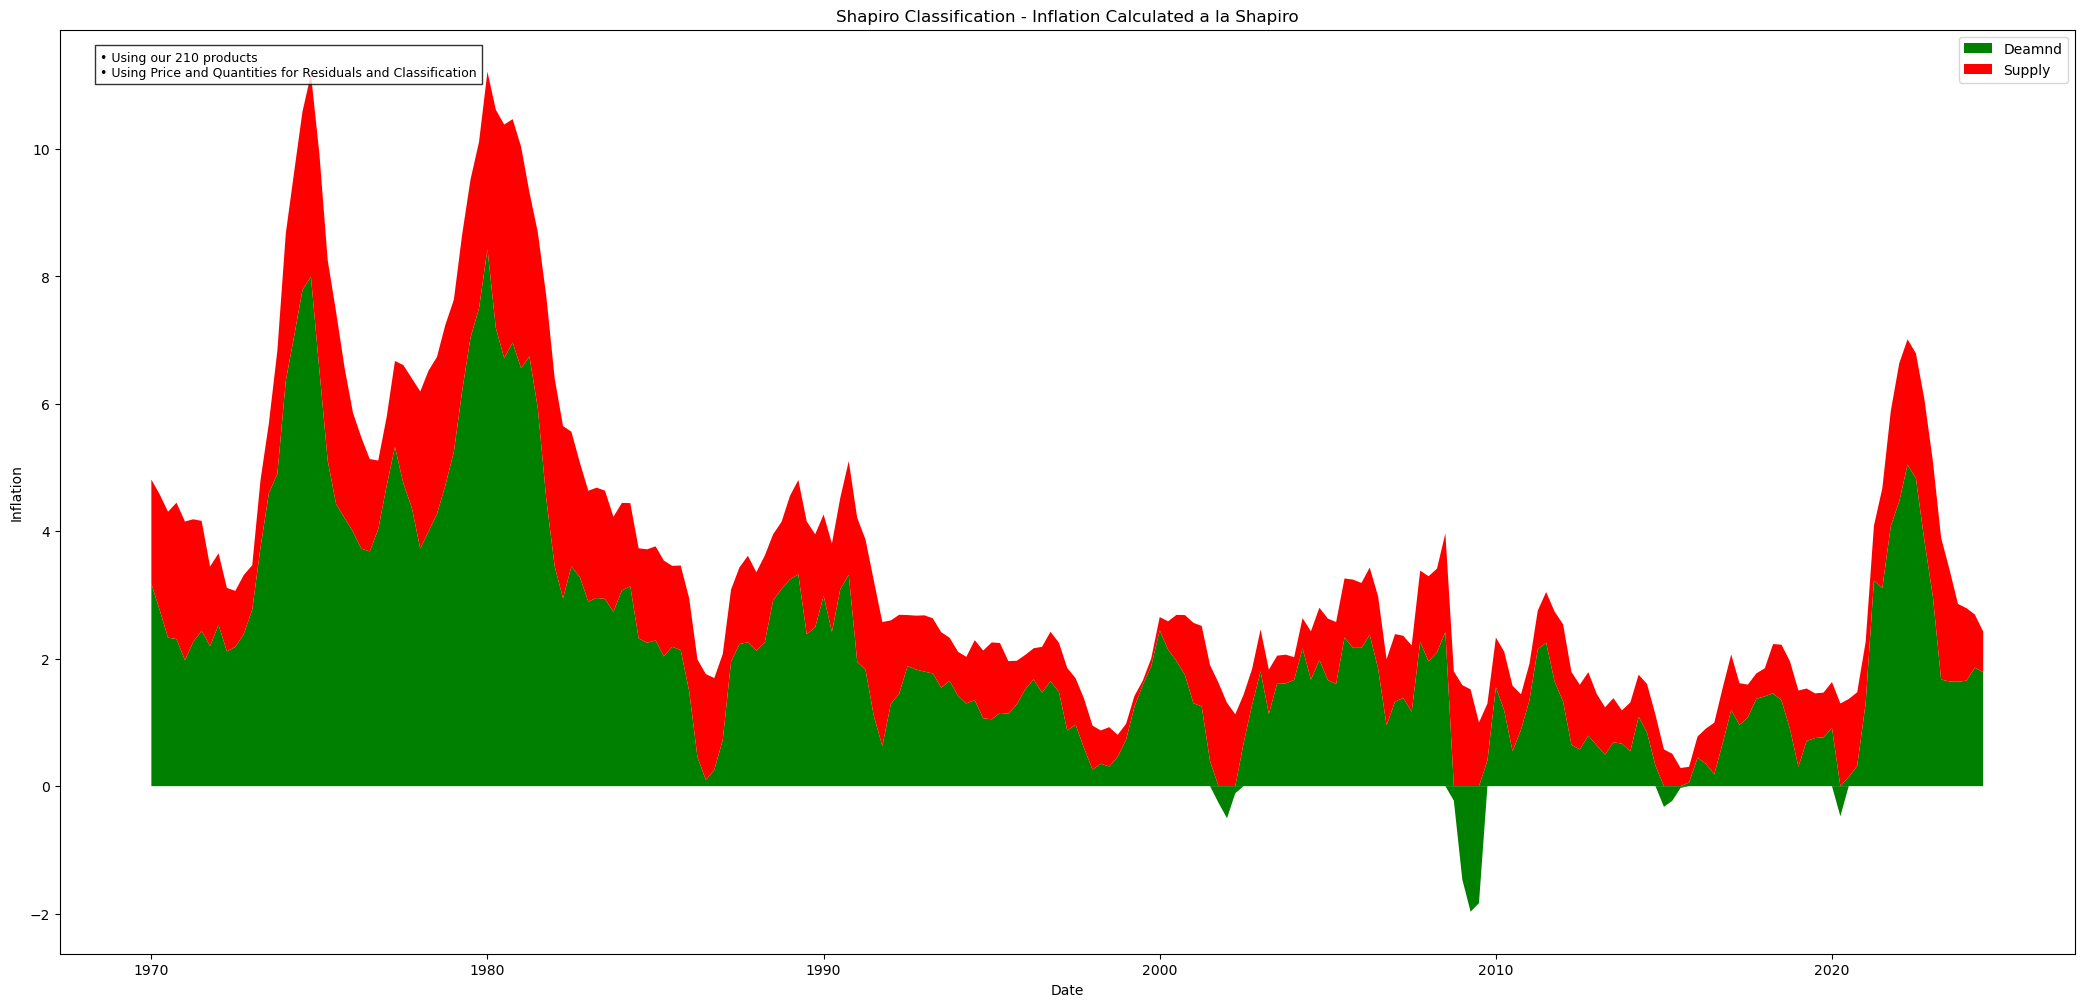

In [ ]:
plot_graphs(inflation_IO_final, "Shapiro Classification - Inflation Calculated a la Shapiro", "• Using our 210 products \n• Using Price and Quantities for Residuals and Classification")